# Классификация спама в электронных письмах методами машинного обучения

**Итоговое домашнее задание по дисциплине «Применение ML в кибербезопасности»**  
**Студент:** Костюхин Иван Максимович  
**Курс:** 2-й курс магистратуры, направление «Кибербезопасность»  
**Среда:** Google Colab, Python

## Цель работы

В этой работе я разрабатываю классификатор электронных писем, который определяет, относится ли сообщение к спаму (`spam = 1`) или к обычной корреспонденции (`ham = 0`). Дополнительное внимание уделяю ложноположительным срабатываниям: ошибочная блокировка обычного письма может привести к потере важной информации.

Для решения задачи я использую два корпуса писем — SpamAssassin и Enron-Spam, сравниваю три алгоритма машинного обучения и провожу отдельную проверку на контрольном архиве из задания.

## План эксперимента

1. Загрузить и исследовать размеченные электронные письма.
2. Очистить тексты, устранить дублирование и разделить данные на обучающую, валидационную и тестовую части.
3. Представить тексты в виде TF-IDF-признаков и сравнить Multinomial Naive Bayes, Logistic Regression и Linear SVM.
4. Выбрать модель и порог классификации **только по валидационной выборке**.
5. Оценить качество на внутреннем тесте и на предоставленном преподавателем наборе `.eml`.
6. Сохранить модель, подготовить FastAPI-сервис, Dockerfile и таблицы с графиками для заполнения заданного преподавателем шаблона презентации.

**Источники данных:** [SpamAssassin Public Corpus](https://spamassassin.apache.org/old/publiccorpus/), [Enron-Spam](https://github.com/MWiechmann/enron_spam_data).

Исследование выполняется на исторических корпусах, преимущественно с англоязычными письмами. Поэтому измеренное качество относится к выбранным данным и не означает одинаковой точности на любом современном почтовом потоке.

## Этап 0. Подготовка программной среды

Для эксперимента использую Google Colab и библиотеки Python: pandas и NumPy для обработки данных, scikit-learn для обучения, Matplotlib и Seaborn для визуализации, FastAPI для проверки работы модели через HTTP. Вычислений на CPU достаточно для выбранных моделей.

Рабочие файлы сохраняю в `/content/antispam_ml`. Исходные письма в публичные результаты не включаю.

In [ ]:
%pip -q install "scikit-learn>=1.3,<2.0" "pandas>=2,<3" "numpy>=1.24,<3" "beautifulsoup4>=4.11" "matplotlib>=3.7" "seaborn>=0.12" "fastapi>=0.105" "uvicorn>=0.25" "httpx>=0.24" joblib

In [ ]:
from pathlib import Path
import io, tarfile, zipfile, urllib.request, time, re, json, sys, html, shutil, importlib.metadata
from email import policy
from email.parser import BytesParser
from email.header import decode_header, make_header
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import joblib

SEED = 42
np.random.seed(SEED)
ROOT = Path('/content/antispam_ml') if Path('/content').exists() else Path.cwd() / 'antispam_ml'
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
SERVICE = ROOT / 'service'
for p in [ROOT, DATA, RESULTS, SERVICE]: p.mkdir(parents=True, exist_ok=True)
print('Каталог проекта:', ROOT)
print('Python:', sys.version.split()[0], '| scikit-learn:', importlib.metadata.version('scikit-learn'))

Каталог проекта: /content/antispam_ml
Python: 3.13.16 | scikit-learn: 1.6.1


## Контрольная выборка из задания

Для независимой проверки использую архив `test_task_emails.tar.xz`, содержащий 1600 писем: 600 обычных и 1000 спам-сообщений. Файл загружается в среду Colab при выполнении следующей ячейки.

Контрольные письма не участвовали в обучении, подборе алгоритма или порога. Совпадающие по тексту письма исключаю из исходных обучающих корпусов до разделения данных, чтобы снизить риск утечки между обучением и внешней проверкой.

In [ ]:
from pathlib import Path
import hashlib
TEACHER_NAME = "test_task_emails.tar.xz"
TEACHER_ARCHIVE = next((p for p in [DATA/TEACHER_NAME, Path("/content")/TEACHER_NAME, Path.cwd()/TEACHER_NAME] if p.is_file()), None)
if TEACHER_ARCHIVE is None:
    try:
        from google.colab import files
    except ImportError as e:
        raise FileNotFoundError(f"Скопируйте {TEACHER_NAME} в {DATA}") from e
    print("Загрузка контрольного архива: test_task_emails.tar.xz")
    uploaded = files.upload()
    if TEACHER_NAME not in uploaded:
        raise ValueError("Контрольная выборка должна быть загружена как test_task_emails.tar.xz")
    TEACHER_ARCHIVE = DATA/TEACHER_NAME
    TEACHER_ARCHIVE.write_bytes(uploaded[TEACHER_NAME])
if not tarfile.is_tarfile(TEACHER_ARCHIVE):
    raise ValueError(f"Некорректный TAR-архив: {TEACHER_ARCHIVE}")
TEACHER_SHA256 = hashlib.sha256(TEACHER_ARCHIVE.read_bytes()).hexdigest()
print("Обязательный тестовый архив:", TEACHER_ARCHIVE, "\nSHA256:", TEACHER_SHA256)

Загрузка контрольного архива: test_task_emails.tar.xz


Saving test_task_emails.tar.xz to test_task_emails.tar.xz
Обязательный тестовый архив: /content/antispam_ml/data/test_task_emails.tar.xz 
SHA256: 14ccf52ab11673a85acab7c9793effa2c8db72c61838ba1b15356bd22d9576ee


### Сохранение результатов в Google Drive (дополнительный вариант)

По умолчанию использую временный каталог Colab. Если требуется хранить результаты непосредственно на Google Диске, для этого предусмотрено подключение Drive в следующей ячейке. При обычном запуске ячейка не нужна.

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')
# ROOT = Path('/content/drive/MyDrive/antispam_ml')
# DATA, RESULTS, SERVICE = ROOT / 'data', ROOT / 'results', ROOT / 'service'
# for p in [ROOT, DATA, RESULTS, SERVICE]: p.mkdir(parents=True, exist_ok=True)

## Этап 1. Сбор исходных данных

Для обучения использую два публичных корпуса. В **SpamAssassin** письма разделены на обычные (`ham`) и нежелательные (`spam`). В **Enron-Spam** доступны тема письма, его текст и соответствующая метка класса.

Объединение нескольких источников позволяет оценивать алгоритмы на более разнообразных текстах. Загрузка корпусов выполняется автоматически с проверкой доступности файлов.

In [ ]:
from urllib.error import URLError, HTTPError

def fetch_with_fallback(urls, dest, min_bytes=1000):
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size >= min_bytes:
        print('В кэше:', dest.name, f'({dest.stat().st_size:,} байт)')
        return dest
    last_error = None
    for url in urls:
        try:
            print('Скачиваем:', url)
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (Colab academic ML project)'})
            with urllib.request.urlopen(req, timeout=100) as resp, open(dest, 'wb') as fout:
                shutil.copyfileobj(resp, fout)
            if dest.stat().st_size < min_bytes:
                raise ValueError('Получен слишком маленький файл вместо архива')
            print('Готово:', dest.name, f'({dest.stat().st_size:,} байт)')
            return dest
        except Exception as err:
            last_error = err
            dest.unlink(missing_ok=True)
            print('Не удалось:', type(err).__name__, str(err)[:180])
    raise RuntimeError(f'Не удалось скачать {dest.name}. Для продолжения файл должен быть расположен в {DATA}. Последняя ошибка: {last_error}')

SPAMASSASSIN_ARCHIVES = {
    '20030228_easy_ham.tar.bz2': 0,
    '20030228_easy_ham_2.tar.bz2': 0,
    '20030228_hard_ham.tar.bz2': 0,
    '20030228_spam.tar.bz2': 1,
    '20050311_spam_2.tar.bz2': 1,
}
base = 'https://spamassassin.apache.org/old/publiccorpus/'
spam_paths = {}
for archive_name, label in SPAMASSASSIN_ARCHIVES.items():
    spam_paths[archive_name] = fetch_with_fallback(
        [base + archive_name, 'https://spamassassin.apache.org/publiccorpus/' + archive_name],
        DATA / archive_name)

ENRON_ARCHIVE = fetch_with_fallback([
    'https://raw.githubusercontent.com/MWiechmann/enron_spam_data/master/enron_spam_data.zip',
    'https://github.com/MWiechmann/enron_spam_data/raw/refs/heads/master/enron_spam_data.zip',
    'https://media.githubusercontent.com/media/MWiechmann/enron_spam_data/master/enron_spam_data.zip',
], DATA / 'enron_spam_data.zip', min_bytes=10000)

Скачиваем: https://spamassassin.apache.org/old/publiccorpus/20030228_easy_ham.tar.bz2
Готово: 20030228_easy_ham.tar.bz2 (1,612,216 байт)
Скачиваем: https://spamassassin.apache.org/old/publiccorpus/20030228_easy_ham_2.tar.bz2
Готово: 20030228_easy_ham_2.tar.bz2 (1,077,892 байт)
Скачиваем: https://spamassassin.apache.org/old/publiccorpus/20030228_hard_ham.tar.bz2
Готово: 20030228_hard_ham.tar.bz2 (1,029,898 байт)
Скачиваем: https://spamassassin.apache.org/old/publiccorpus/20030228_spam.tar.bz2
Готово: 20030228_spam.tar.bz2 (1,183,768 байт)
Скачиваем: https://spamassassin.apache.org/old/publiccorpus/20050311_spam_2.tar.bz2
Готово: 20050311_spam_2.tar.bz2 (2,059,029 байт)
Скачиваем: https://raw.githubusercontent.com/MWiechmann/enron_spam_data/master/enron_spam_data.zip
Готово: enron_spam_data.zip (15,642,124 байт)


In [ ]:
def readable_text_from_email(raw_bytes):
    """Извлекает только Subject и текстовую часть; заголовки-маркеры корпуса не используются."""
    try:
        message = BytesParser(policy=policy.default).parsebytes(raw_bytes)
        try:
            subject = str(make_header(decode_header(str(message.get('Subject', '')))))
        except Exception:
            subject = str(message.get('Subject', ''))
        plain, html_parts = [], []
        for part in message.walk():
            if part.is_multipart() or part.get_content_disposition() == 'attachment':
                continue
            content_type = part.get_content_type()
            if content_type not in ('text/plain', 'text/html'):
                continue
            payload = part.get_payload(decode=True)
            if payload is None:
                continue
            encoding = part.get_content_charset() or 'utf-8'
            try:
                part_text = payload.decode(encoding, errors='replace')
            except LookupError:
                part_text = payload.decode('utf-8', errors='replace')
            if content_type == 'text/plain':
                plain.append(part_text)
            else:
                html_parts.append(BeautifulSoup(part_text, 'html.parser').get_text(' ', strip=True))
        body = ' '.join(plain) if plain else ' '.join(html_parts)
        return (subject + ' ' + body).strip()[:30000]
    except Exception:
        # Резервная обработка писем, не соответствующих ожидаемому MIME-формату.
        return raw_bytes.decode('utf-8', errors='replace')[:30000]

def parse_spamassassin(archive_paths):
    rows = []
    for archive_name, path in archive_paths.items():
        label = SPAMASSASSIN_ARCHIVES[archive_name]
        amount = 0
        with tarfile.open(path, mode='r:bz2') as archive:
            for member in archive:
                if not member.isfile() or member.size > 3_000_000:
                    continue
                if Path(member.name).name.lower() in {'cmds', 'readme', 'readme.txt'}:
                    continue
                handle = archive.extractfile(member)
                if handle is None:
                    continue
                text = readable_text_from_email(handle.read())
                if len(text.strip()) >= 8:
                    rows.append({'text': text, 'label': label, 'source': 'SpamAssassin'})
                    amount += 1
        print(f'{archive_name}: {amount} писем')
    return pd.DataFrame(rows)

def parse_enron(path):
    with zipfile.ZipFile(path) as zf:
        candidates = [name for name in zf.namelist() if name.lower().endswith('.csv') and not name.startswith('__MACOSX')]
        if not candidates:
            raise ValueError('В архиве Enron не найден CSV: ' + str(zf.namelist()[:10]))
        with zf.open(candidates[0]) as file:
            raw = pd.read_csv(file, encoding='latin1', low_memory=False)
    raw.columns = [str(col).strip() for col in raw.columns]
    expected = {'Subject', 'Message', 'Spam/Ham'}
    if not expected.issubset(raw.columns):
        raise ValueError(f'Неожиданные поля Enron: {list(raw.columns)}')
    labels = raw['Spam/Ham'].astype(str).str.strip().str.lower().map({'spam': 1, 'ham': 0})
    txt = raw['Subject'].fillna('').astype(str) + ' ' + raw['Message'].fillna('').astype(str)
    data = pd.DataFrame({'text': txt.str.slice(0, 30000), 'label': labels, 'source': 'Enron-Spam'})
    return data.dropna(subset=['label']).astype({'label': 'int64'})

### Чтение контрольных писем

Из файлов `.eml` извлекаю тему и текст сообщения. Для HTML-писем преобразую содержимое в обычный текст. В контрольной выборке сохраняю все предоставленные письма, в том числе повторяющиеся и пустые, чтобы количество проверенных объектов соответствовало исходному заданию.

Архив читается напрямую без распаковки содержимого в рабочую директорию.

In [ ]:
from pathlib import PurePosixPath

def parse_teacher_archive(path):
    rows = []
    with tarfile.open(path, mode="r:xz") as tf:
        for member in tf:
            if not member.isfile():
                continue
            parts = PurePosixPath(member.name).parts
            if len(parts) != 2 or parts[0] not in ("ham", "spam") or not parts[1].lower().endswith(".eml"):
                continue
            if member.size > 3_000_000:
                raise ValueError("Очень большое письмо: " + member.name)
            f = tf.extractfile(member)
            if f is None:
                raise ValueError("Ошибка чтения: " + member.name)
            rows.append({"file":member.name, "label":int(parts[0]=="spam"),
                         "text":readable_text_from_email(f.read())})
    t = pd.DataFrame(rows)
    if t.empty or set(t.label)!={0,1} or t.file.duplicated().any():
        raise ValueError("Некорректный контрольный архив: нужны уникальные пути ham/*.eml и spam/*.eml")
    t["text"] = t.text.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    return t.reset_index(drop=True)

teacher_df = parse_teacher_archive(TEACHER_ARCHIVE)
teacher_duplicate_count = int(teacher_df.text.str.lower().duplicated().sum())
teacher_empty_count = int((teacher_df.text.str.len() < 8).sum())
print(f"Писем преподавателя: {len(teacher_df)}; ham={(teacher_df.label==0).sum()}; spam={(teacher_df.label==1).sum()}")
print(f"Повторы текста: {teacher_duplicate_count}; письма короче 8 символов: {teacher_empty_count}")
if len(teacher_df) != 1600:
    raise ValueError("Ожидается исходный набор преподавателя из 1600 писем")


Писем преподавателя: 1600; ham=600; spam=1000
Повторы текста: 56; письма короче 8 символов: 2


In [ ]:
sa_df = parse_spamassassin(spam_paths)
enron_df = parse_enron(ENRON_ARCHIVE)
print('До очистки:', len(sa_df), 'SpamAssassin,', len(enron_df), 'Enron-Spam')
df = pd.concat([sa_df, enron_df], ignore_index=True)
df['text'] = df['text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
df = df[df['text'].str.len() >= 8].copy()
# Исключаю точные пересечения с контрольной выборкой до разделения данных.
teacher_keys = set(teacher_df.text.str.lower())
overlap_mask = df.text.str.lower().isin(teacher_keys)
excluded_teacher_overlaps = int(overlap_mask.sum())
print("Исключено точных совпадений с контрольным тестом из обучающих корпусов:",excluded_teacher_overlaps)
df = df.loc[~overlap_mask].copy()
# Удаляю дубликаты и тексты с противоречивыми метками до разделения.
df['_key'] = df['text'].str.lower()
conflicts = df.groupby('_key')['label'].nunique()
conflict_keys = set(conflicts[conflicts > 1].index)
print('Конфликтующих текстов:', len(conflict_keys))
df = df[~df['_key'].isin(conflict_keys)].drop_duplicates('_key', keep='first').drop(columns='_key').reset_index(drop=True)
assert set(df['label']) == {0, 1} and df['source'].nunique() == 2, 'Проверьте данные: нужны оба класса из двух источников'
print('После очистки:', len(df))
display(pd.crosstab(df['source'], df['label']).rename(columns={0:'ham', 1:'spam'}))

20030228_easy_ham.tar.bz2: 2500 писем
20030228_easy_ham_2.tar.bz2: 1400 писем
20030228_hard_ham.tar.bz2: 250 писем
20030228_spam.tar.bz2: 500 писем
20050311_spam_2.tar.bz2: 1396 писем
До очистки: 6046 SpamAssassin, 33716 Enron-Spam
Исключено точных совпадений с контрольным тестом из обучающих корпусов: 1230
Конфликтующих текстов: 0
После очистки: 34873


label,ham,spam
source,,
Enron-Spam,15587,14538
SpamAssassin,3571,1177


### Очистка и разделение набора данных

Перед обучением удаляю точные повторы текстов и сообщения с противоречивыми метками. Это позволяет не допустить попадания одинаковых писем в разные части эксперимента.

Разделяю выборку на **train — 64%**, **validation — 16%** и **test — 20%**. Стратификацию выполняю одновременно по метке класса и источнику письма: так сохраняется сопоставимость распределений. Внутреннюю тестовую часть не использую при настройке моделей.

train     :  22318 | spam = 45.07%


label,ham,spam
source,,
Enron-Spam,9975,9304
SpamAssassin,2285,754


validation:   5580 | spam = 45.05%


label,ham,spam
source,,
Enron-Spam,2494,2326
SpamAssassin,572,188


test      :   6975 | spam = 45.06%


label,ham,spam
source,,
Enron-Spam,3118,2908
SpamAssassin,714,235


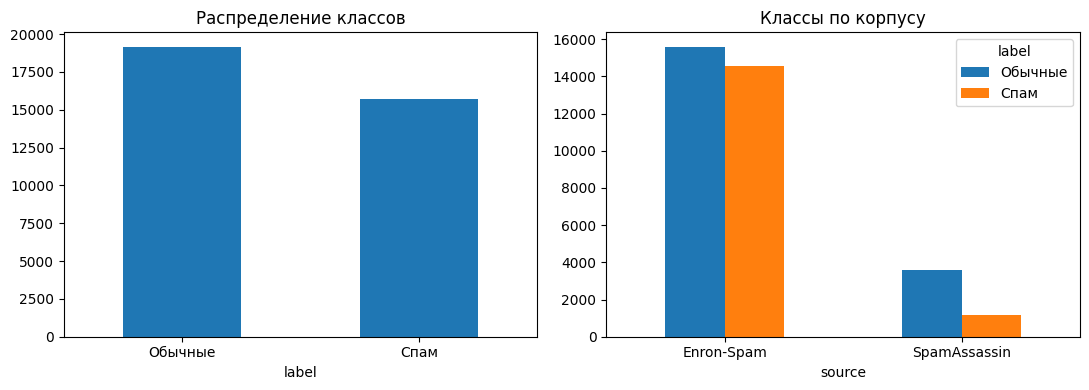

Данные для слайда о корпусах сохранены: dataset_summary.csv, dataset_split.csv


In [ ]:
strata = df['source'].astype(str) + '__' + df['label'].astype(str)
trainval, test_df = train_test_split(df, test_size=0.20, stratify=strata, random_state=SEED)
strata_trainval = trainval['source'].astype(str) + '__' + trainval['label'].astype(str)
train_df, val_df = train_test_split(trainval, test_size=0.20, stratify=strata_trainval, random_state=SEED)
train_df, val_df, test_df = [x.reset_index(drop=True) for x in (train_df, val_df, test_df)]
for name, part in [('train',train_df),('validation',val_df),('test',test_df)]:
    print(f'{name:10s}: {len(part):6d} | spam = {part.label.mean():.2%}')
    display(pd.crosstab(part.source, part.label).rename(columns={0:'ham',1:'spam'}))

fig, axes = plt.subplots(1, 2, figsize=(11,4))
df['label'].map({0:'Обычные',1:'Спам'}).value_counts().plot.bar(ax=axes[0], rot=0, title='Распределение классов')
pd.crosstab(df.source, df.label).rename(columns={0:'Обычные',1:'Спам'}).plot.bar(ax=axes[1], title='Классы по корпусу', rot=0)
plt.tight_layout(); plt.savefig(RESULTS / '01_dataset_distribution.png', dpi=160); plt.show()
# Сводная таблица для описания источников и разбиения в заданном шаблоне презентации.
dataset_summary = (df.groupby(['source', 'label']).size()
                   .unstack(fill_value=0).rename(columns={0: 'ham', 1: 'spam'}))
dataset_summary['total'] = dataset_summary.sum(axis=1)
dataset_summary.to_csv(RESULTS / 'dataset_summary.csv', encoding='utf-8-sig')
split_rows = []
for split_name, split_data in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    for src_name in sorted(split_data.source.unique()):
        sub = split_data[split_data.source == src_name]
        split_rows.append({'split': split_name, 'source': src_name,
                           'ham': int((sub.label == 0).sum()),
                           'spam': int((sub.label == 1).sum()),
                           'total': len(sub)})
pd.DataFrame(split_rows).to_csv(RESULTS / 'dataset_split.csv', index=False, encoding='utf-8-sig')
print('Данные для слайда о корпусах сохранены: dataset_summary.csv, dataset_split.csv')


## Этап 2. Обучение и сравнение моделей

Для представления текстов использую **TF-IDF** с отдельными словами и биграммами. TF-IDF учитывает частоту слова внутри письма и его распространённость в корпусе, позволяя выделять информативные признаки.

Сравниваю три метода: **Multinomial Naive Bayes**, **Logistic Regression** и **Linear SVM с калибровкой оценок вероятности**. Для каждого строю единый Pipeline из векторизатора и классификатора. Применяю трёхкратную стратифицированную кросс-валидацию на обучающей части.

Считаю **Accuracy, Precision, Recall и F1**. Дополнительно измеряю **FP** (обычные письма, ошибочно признанные спамом) и **FPR** (долю таких ошибок среди обычных писем).

In [ ]:
def build_pipeline(estimator):
    return Pipeline([
        ('tfidf', TfidfVectorizer(lowercase=True, strip_accents='unicode',
                                  sublinear_tf=True, ngram_range=(1,2),
                                  min_df=2, max_df=0.99, max_features=60000)),
        ('model', estimator)
    ])

MODELS = {
    'Multinomial Naive Bayes': lambda: build_pipeline(MultinomialNB(alpha=0.5)),
    'Logistic Regression': lambda: build_pipeline(LogisticRegression(max_iter=800, class_weight='balanced', random_state=SEED)),
    'Linear SVM (calibrated)': lambda: build_pipeline(CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=SEED), method='sigmoid', cv=3)),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_rows = []
for name, factory in MODELS.items():
    print('Кросс-валидация:', name)
    t0 = time.time()
    fold_results = cross_validate(
        factory(), train_df.text, train_df.label, cv=cv, n_jobs=1,
        scoring={'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1'},
        error_score='raise')
    row = {'model': name, 'seconds': round(time.time()-t0, 1)}
    for metric in ('accuracy','precision','recall','f1'):
        row[f'cv_{metric}_mean'] = float(fold_results['test_'+metric].mean())
        row[f'cv_{metric}_std'] = float(fold_results['test_'+metric].std())
    cv_rows.append(row)
cv_df = pd.DataFrame(cv_rows).sort_values('cv_f1_mean', ascending=False)
cv_df.to_csv(RESULTS/'cv_metrics.csv', index=False)
display(cv_df.style.format({c: '{:.3f}' for c in cv_df if c.startswith('cv_')}))

Кросс-валидация: Multinomial Naive Bayes
Кросс-валидация: Logistic Regression
Кросс-валидация: Linear SVM (calibrated)


,model,seconds,cv_accuracy_mean,cv_accuracy_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
2,Linear SVM (calibrated),36.600000,0.988,0.002,0.986,0.001,0.989,0.003,0.987,0.002
1,Logistic Regression,36.500000,0.983,0.002,0.973,0.002,0.989,0.003,0.981,0.002
0,Multinomial Naive Bayes,42.500000,0.983,0.002,0.987,0.002,0.975,0.002,0.981,0.002


### Выбор порога классификации

Стандартный порог вероятности спама равен 0,5, однако для почтового фильтра типы ошибок имеют разную стоимость. **FP** означает, что полезное письмо ошибочно помечено как спам; **FN** означает, что спам не был обнаружен.

На валидационной выборке подбираю порог, минимизирующий FPR при **Recall спама не ниже 90%**. Это принятое мной условие эксперимента, а не отдельное требование задания. Если выполнить его невозможно, использую порог с максимальным F1 и фиксирую ограничение результата.

Обучаем модель: Multinomial Naive Bayes
Обучаем модель: Logistic Regression
Обучаем модель: Linear SVM (calibrated)


,model,threshold,recall_constraint_met,accuracy,precision,recall,f1,fp,fpr
0,Linear SVM (calibrated),0.97,True,0.9579,0.9961,0.9101,0.9512,9,0.0029
1,Logistic Regression,0.79,True,0.9550,0.9939,0.9057,0.9478,14,0.0046
2,Multinomial Naive Bayes,0.87,True,0.9548,0.9922,0.9069,0.9476,18,0.0059


Лучшая модель по validation: Linear SVM (calibrated), порог 0.97


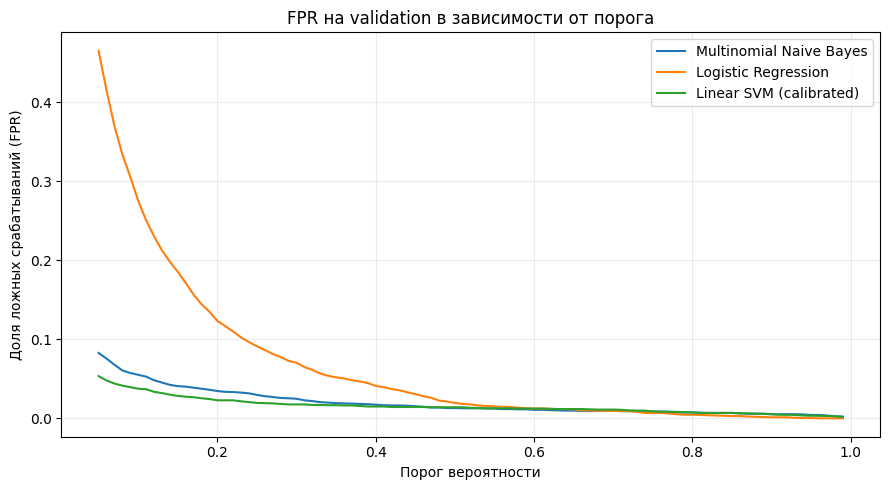

In [ ]:
def evaluate(y_true, prob_spam, threshold):
    pred = (np.asarray(prob_spam) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    return {'accuracy':float(accuracy_score(y_true,pred)),
            'precision':float(precision_score(y_true,pred,zero_division=0)),
            'recall':float(recall_score(y_true,pred,zero_division=0)),
            'f1':float(f1_score(y_true,pred,zero_division=0)),
            'tn':int(tn), 'fp':int(fp), 'fn':int(fn), 'tp':int(tp),
            'fpr':float(fp / (fp + tn)) if fp+tn else 0.0}

def choose_threshold(y_true, proba, min_recall=0.90):
    candidates = np.round(np.linspace(0.05,0.99,95), 3)
    rows = [{'threshold':float(t), **evaluate(y_true, proba, t)} for t in candidates]
    table = pd.DataFrame(rows)
    feasible = table[table.recall >= min_recall]
    if len(feasible):
        chosen = feasible.sort_values(['fpr','f1','recall','threshold'], ascending=[True,False,False,False]).iloc[0]
        return float(chosen.threshold), True, table
    chosen = table.sort_values(['f1','fpr'], ascending=[False,True]).iloc[0]
    return float(chosen.threshold), False, table

trained = {}
val_rows, curves = [], {}
for name, factory in MODELS.items():
    print('Обучаем модель:', name)
    model = factory().fit(train_df.text,train_df.label)
    p_val = model.predict_proba(val_df.text)[:,1]
    threshold, meets, curve = choose_threshold(val_df.label, p_val)
    metrics = evaluate(val_df.label, p_val, threshold)
    val_rows.append({'model':name, 'threshold':threshold, 'recall_constraint_met':bool(meets), **metrics})
    trained[name] = model
    curves[name] = curve
val_table = pd.DataFrame(val_rows).sort_values(['recall_constraint_met','fpr','f1'],ascending=[False,True,False]).reset_index(drop=True)
val_table.to_csv(RESULTS/'validation_metrics.csv',index=False)
display(val_table[['model','threshold','recall_constraint_met','accuracy','precision','recall','f1','fp','fpr']].round(4))

# Выбор модели и порога выполняю только по validation.
BEST_NAME = str(val_table.iloc[0]['model'])
BEST_THRESHOLD = float(val_table.iloc[0]['threshold'])
BEST_MODEL = trained[BEST_NAME]
print(f'Лучшая модель по validation: {BEST_NAME}, порог {BEST_THRESHOLD:.2f}')
if not bool(val_table.iloc[0]['recall_constraint_met']):
    print('Внимание: ограничение Recall >= 0.90 не достигнуто выбранной моделью!')

fig, ax = plt.subplots(figsize=(9,5))
for name, curve in curves.items():
    ax.plot(curve.threshold, curve.fpr, label=name)
ax.set(xlabel='Порог вероятности',ylabel='Доля ложных срабатываний (FPR)',title='FPR на validation в зависимости от порога')
ax.legend(); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig(RESULTS/'02_fpr_threshold.png',dpi=160); plt.show()

### Оценка моделей на внутренней тестовой выборке

После выбора модели и порога выполняю проверку на отложенном тесте. Для анализа использую таблицу метрик, матрицу ошибок и показатели отдельно по двум исходным корпусам.

Результаты тестирования не использую для повторного подбора параметров: иначе оценка могла бы оказаться завышенной.

,model,threshold,accuracy,precision,recall,f1,fp,fn,fpr
2,Linear SVM (calibrated),0.97,0.9596,0.9983,0.9119,0.9531,5,277,0.0013
1,Logistic Regression,0.79,0.9578,0.9965,0.9096,0.9511,10,284,0.0026
0,Multinomial Naive Bayes,0.87,0.9528,0.9951,0.8998,0.9450,14,315,0.0037



Финальная модель: Linear SVM (calibrated)
               precision    recall  f1-score   support

ham / обычное       0.93      1.00      0.96      3832
         spam       1.00      0.91      0.95      3143

     accuracy                           0.96      6975
    macro avg       0.97      0.96      0.96      6975
 weighted avg       0.96      0.96      0.96      6975

Ложно отнесено к спаму: 5 обычных писем (FPR = 0.13%)
Требование точности выше 86%: ДОСТИГНУТО


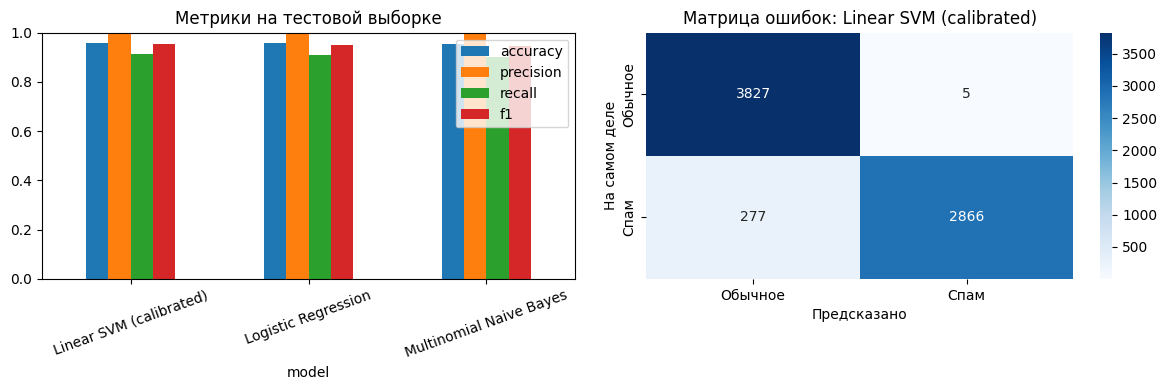

Качество отдельно по источникам:


,source,count,accuracy,precision,recall,f1,tn,fp,fn,tp,fpr
0,Enron-Spam,6026,0.9569,0.9989,0.9116,0.9533,3115,3,257,2651,0.0010
1,SpamAssassin,949,0.9768,0.9908,0.9149,0.9513,712,2,20,215,0.0028


Примеры ошибок (до 10):


,source,label,predicted,short_text
17,Enron-Spam,1,0,"pictures face lone machine again , write . oxy..."
22,Enron-Spam,1,0,"please help , new webcam / modeling page i jus..."
96,Enron-Spam,1,0,prissy abe dainty bifocal kalmia coarsen bob c...
109,Enron-Spam,1,0,"i am so happy "" do i have to dress for the nex..."
121,Enron-Spam,1,0,find that special someone
167,Enron-Spam,1,0,- just in time for school - get the family a d...
226,Enron-Spam,1,0,this is a legitimate way for you to secure spe...
234,SpamAssassin,1,0,拾金不昧~~別傻了~~
239,Enron-Spam,1,0,did you know that there are schools in the wor...
243,Enron-Spam,1,0,anal s 3 x please let the image load . . . clo...


In [ ]:
test_rows, test_probs = [], {}
for name, model in trained.items():
    p_test = model.predict_proba(test_df.text)[:,1]
    threshold = float(val_table.set_index('model').loc[name, 'threshold'])
    test_probs[name] = p_test
    test_rows.append({'model':name,'threshold':threshold,**evaluate(test_df.label,p_test,threshold)})
test_table = pd.DataFrame(test_rows).sort_values('f1',ascending=False)
test_table.to_csv(RESULTS/'test_metrics.csv', index=False)
display(test_table[['model','threshold','accuracy','precision','recall','f1','fp','fn','fpr']].round(4))

best_prob = test_probs[BEST_NAME]
best_pred = (best_prob >= BEST_THRESHOLD).astype(int)
final = evaluate(test_df.label, best_prob, BEST_THRESHOLD)
print('\nФинальная модель:',BEST_NAME)
print(classification_report(test_df.label,best_pred,target_names=['ham / обычное','spam'],zero_division=0))
print(f"Ложно отнесено к спаму: {final['fp']} обычных писем (FPR = {final['fpr']:.2%})")
print('Требование точности выше 86%:', 'ДОСТИГНУТО' if final['accuracy']>0.86 else 'НЕ ДОСТИГНУТО')

fig, axes=plt.subplots(1,2,figsize=(12,4))
metrics_plot=test_table.set_index('model')[['accuracy','precision','recall','f1']]
metrics_plot.plot.bar(ax=axes[0],rot=20,ylim=(0,1),title='Метрики на тестовой выборке')
cm=confusion_matrix(test_df.label,best_pred,labels=[0,1])
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',ax=axes[1],xticklabels=['Обычное','Спам'],yticklabels=['Обычное','Спам'])
axes[1].set(xlabel='Предсказано',ylabel='На самом деле',title='Матрица ошибок: '+BEST_NAME)
plt.tight_layout();plt.savefig(RESULTS/'03_test_metrics_confusion.png',dpi=160);plt.show()

source_rows=[]
for source, idx in test_df.groupby('source').groups.items():
    source_rows.append({'source':source,'count':len(idx),**evaluate(test_df.loc[idx,'label'],best_prob[np.asarray(list(idx))],BEST_THRESHOLD)})
source_metrics=pd.DataFrame(source_rows)
source_metrics.to_csv(RESULTS/'test_by_dataset.csv',index=False)
print('Качество отдельно по источникам:')
display(source_metrics.round(4))

errors=test_df.loc[best_pred != test_df.label.to_numpy(), ['source','label','text']].copy()
errors['predicted']=best_pred[best_pred != test_df.label.to_numpy()]
errors['short_text']=errors['text'].str.slice(0,150).str.replace(r'\s+',' ',regex=True)
errors[['source','label','predicted','short_text']].head(20).to_csv(RESULTS/'error_examples.csv',index=False)
print('Примеры ошибок (до 10):')
display(errors[['source','label','predicted','short_text']].head(10))

### Проверка на тестовом архиве преподавателя

Отдельно оцениваю зафиксированную модель на предоставленных 1600 сообщениях. Рассчитываю Accuracy, Precision, Recall, F1, FP, FN и FPR, строю матрицу ошибок и сохраняю предсказания для каждого файла в CSV.

Повторяющиеся письма учитываю в общем результате, поскольку они входят в исходный контрольный архив. Для дополнительного сравнения отдельно рассчитываю показатели на уникальных текстах.


=== КОНТРОЛЬНЫЙ ТЕСТ ПРЕПОДАВАТЕЛЯ ===
Accuracy: 86.75%; Precision: 99.37%; Recall: 79.30%; F1: 88.21%
FP: 5; FN: 207; FPR: 0.83%
Accuracy строго выше 86%: ДА
              precision    recall  f1-score   support

         ham       0.74      0.99      0.85       600
        spam       0.99      0.79      0.88      1000

    accuracy                           0.87      1600
   macro avg       0.87      0.89      0.87      1600
weighted avg       0.90      0.87      0.87      1600



,test,accuracy,precision,recall,f1,tn,fp,fn,tp,fpr
0,все 1600,0.8675,0.9937,0.7930,0.8821,595,5,207,793,0.0083
1,уникальные тексты,0.8679,0.9934,0.7914,0.8810,585,5,199,755,0.0085


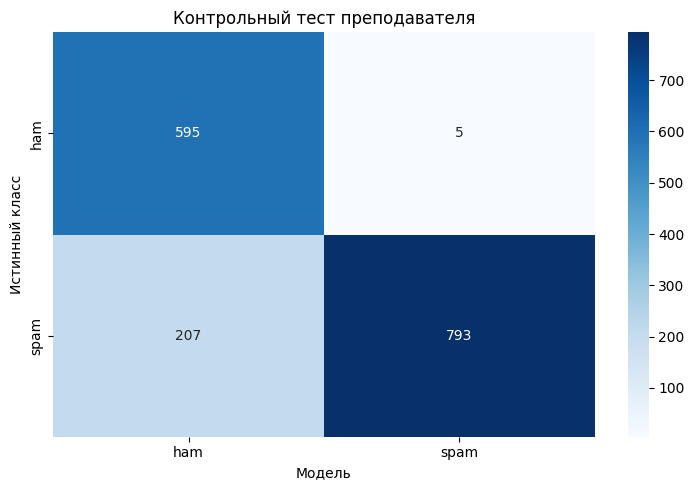

Примеры ошибочных предсказаний:


,file,actual_spam,predicted_spam,spam_probability,correct
8,ham/008.eml,0,1,0.977232,False
185,ham/185.eml,0,1,0.986011,False
328,ham/328.eml,0,1,0.976539,False
445,ham/445.eml,0,1,0.994274,False
540,ham/540.eml,0,1,0.992276,False
604,spam/004.eml,1,0,0.739697,False
616,spam/016.eml,1,0,0.915746,False
617,spam/017.eml,1,0,0.614552,False
621,spam/021.eml,1,0,0.935819,False
622,spam/022.eml,1,0,0.897250,False


In [ ]:
# Контрольная оценка проводится после фиксации модели и порога на validation.
teacher_proba = BEST_MODEL.predict_proba(teacher_df.text)[:,1]
teacher_pred = (teacher_proba >= BEST_THRESHOLD).astype(int)
teacher_metrics = evaluate(teacher_df.label, teacher_proba, BEST_THRESHOLD)
teacher_predictions = teacher_df[["file","label"]].rename(columns={"label":"actual_spam"}).copy()
teacher_predictions["predicted_spam"] = teacher_pred
teacher_predictions["spam_probability"] = teacher_proba.round(6)
teacher_predictions["correct"] = teacher_predictions.actual_spam == teacher_predictions.predicted_spam
teacher_predictions.to_csv(RESULTS/"teacher_test_predictions.csv",index=False)
unique_mask = ~teacher_df.text.str.lower().duplicated()
teacher_unique_metrics = evaluate(teacher_df.loc[unique_mask,"label"],teacher_proba[unique_mask.to_numpy()], BEST_THRESHOLD)
teacher_summary = {"archive":TEACHER_NAME,"sha256":TEACHER_SHA256,
                   "count":int(len(teacher_df)), "ham":int((teacher_df.label==0).sum()),
                   "spam":int((teacher_df.label==1).sum()),"duplicate_texts":teacher_duplicate_count,
                   "short_or_empty":teacher_empty_count,"excluded_train_overlaps":excluded_teacher_overlaps,
                   "model":BEST_NAME,"threshold":BEST_THRESHOLD,"metrics":teacher_metrics,
                   "unique_text_metrics":teacher_unique_metrics}
(RESULTS/"teacher_test_summary.json").write_text(json.dumps(teacher_summary,ensure_ascii=False,indent=2),encoding="utf-8")
print("\n=== КОНТРОЛЬНЫЙ ТЕСТ ПРЕПОДАВАТЕЛЯ ===")
print(f"Accuracy: {teacher_metrics['accuracy']:.2%}; Precision: {teacher_metrics['precision']:.2%}; Recall: {teacher_metrics['recall']:.2%}; F1: {teacher_metrics['f1']:.2%}")
print(f"FP: {teacher_metrics['fp']}; FN: {teacher_metrics['fn']}; FPR: {teacher_metrics['fpr']:.2%}")
print("Accuracy строго выше 86%:", "ДА" if teacher_metrics['accuracy']>.86 else "НЕТ")
print(classification_report(teacher_df.label,teacher_pred,target_names=["ham","spam"],zero_division=0))
display(pd.DataFrame([{"test":"все 1600",**teacher_metrics},{"test":"уникальные тексты",**teacher_unique_metrics}]).round(4))
fig,ax=plt.subplots(figsize=(7.5,5))
sns.heatmap(confusion_matrix(teacher_df.label,teacher_pred,labels=[0,1]),annot=True,fmt="d",cmap="Blues",
            xticklabels=["ham","spam"],yticklabels=["ham","spam"],ax=ax)
ax.set(title="Контрольный тест преподавателя",xlabel="Модель",ylabel="Истинный класс")
plt.tight_layout();plt.savefig(RESULTS/"04_teacher_confusion.png",dpi=170);plt.show()
print("Примеры ошибочных предсказаний:")
display(teacher_predictions.loc[~teacher_predictions.correct].head(12))

### Анализ классификационных ошибок

Одна только Accuracy не показывает, как модель ошибается. Поэтому я отдельно рассматриваю два случая:

- **False Positive (FP)** — обычное письмо распознано как спам; потенциально это более критичная ошибка для пользователя.
- **False Negative (FN)** — спам распознан как обычное письмо; снижается эффективность фильтрации.

Для анализа вывожу количество ошибок, имена соответствующих файлов, рассчитанные вероятности и длину писем. Содержимое контрольных писем не включаю в публичные материалы.

In [ ]:
# Просмотр классификационных ошибок на контрольном архиве без повторного обучения
error_view = teacher_predictions.copy()
error_view['text_length'] = teacher_df.text.str.len().to_numpy()
error_view['error_type'] = np.select(
    [
        (error_view.actual_spam == 0) & (error_view.predicted_spam == 1),
        (error_view.actual_spam == 1) & (error_view.predicted_spam == 0),
    ], ['FP: обычное письмо -> спам','FN: спам -> обычное'], default='Верно'
)
print('Ошибки по типам:')
display(error_view.error_type.value_counts().rename_axis('Тип').reset_index(name='Количество'))
print('Примеры ложных срабатываний (FP):')
display(error_view.loc[error_view.error_type.str.startswith('FP'),
       ['file','spam_probability','text_length']].head(7))
print('Примеры пропущенного спама (FN):')
display(error_view.loc[error_view.error_type.str.startswith('FN'),
       ['file','spam_probability','text_length']].head(7))
print('Для анализа использую метаданные ошибок, без публикации содержимого писем.')

Ошибки по типам:


,Тип,Количество
0,Верно,1388
1,FN: спам -> обычное,207
2,FP: обычное письмо -> спам,5


Примеры ложных срабатываний (FP):


,file,spam_probability,text_length
8,ham/008.eml,0.977232,790
185,ham/185.eml,0.986011,181
328,ham/328.eml,0.976539,826
445,ham/445.eml,0.994274,138
540,ham/540.eml,0.992276,8435


Примеры пропущенного спама (FN):


,file,spam_probability,text_length
604,spam/004.eml,0.739697,632
616,spam/016.eml,0.915746,2484
617,spam/017.eml,0.614552,1425
621,spam/021.eml,0.935819,353
622,spam/022.eml,0.897250,2682
626,spam/026.eml,0.752333,1121
633,spam/033.eml,0.163635,4092


Для анализа использую метаданные ошибок, без публикации содержимого писем.


### Проверка работы классификатора на отдельных примерах

Дополнительно подаю модели несколько коротких сообщений и сравниваю полученные вероятности спама. Эти примеры позволяют проверить порядок вызова модели, но не заменяют оценку качества на размеченных тестовых данных.

Поскольку обучение проходит преимущественно на англоязычных данных, результат для русскоязычных текстов рассматриваю только как демонстрацию.

In [ ]:
examples = [
    'Subject: Project status\nHi team, please review the attached report before our meeting tomorrow.',
    'Subject: Claim your prize\nCONGRATULATIONS! You have won a cash prize. Click now to claim the money.',
    'Subject: Invoice for October\nHello, attached is our monthly invoice. Please confirm payment.',
    'Subject: Limited offer\nACT NOW! Earn $5000 per week from home. Guaranteed income!',
    'Тема: Встреча кафедры. Просьба подтвердить участие в семинаре завтра.',
]
pr = BEST_MODEL.predict_proba(examples)[:,1]
display(pd.DataFrame({'text':[x[:82] for x in examples], 'spam_probability':pr.round(4),
                      'prediction':['СПАМ' if p>=BEST_THRESHOLD else 'ОБЫЧНОЕ' for p in pr]}))

,text,spam_probability,prediction
0,"Subject: Project status\nHi team, please revie...",0.0041,ОБЫЧНОЕ
1,Subject: Claim your prize\nCONGRATULATIONS! Yo...,0.9924,СПАМ
2,"Subject: Invoice for October\nHello, attached ...",0.1663,ОБЫЧНОЕ
3,Subject: Limited offer\nACT NOW! Earn $5000 pe...,0.9991,СПАМ
4,Тема: Встреча кафедры. Просьба подтвердить уча...,0.8480,ОБЫЧНОЕ


## Обсуждение критериев качества

Для антиспам-задачи считаю важным не только общий процент правильных ответов, но и баланс между полнотой обнаружения спама и сохранением обычных писем. Для этого использую **Precision, Recall, F1 и FPR**, а выбор порога провожу на отдельной валидационной выборке.

После выполнения ячеек экспериментальные результаты сохраняются в таблицах и графиках. Итоговая содержательная интерпретация будет включена в отчёт по полученным значениям и материалам защиты.

In [ ]:
# Итоговые показатели эксперимента, рассчитанные по фактическим предсказаниям.
comparison = pd.DataFrame([
    {'Выборка': 'Внутренний тест', 'Accuracy': final['accuracy'],
     'Precision': final['precision'], 'Recall': final['recall'],
     'F1': final['f1'], 'FP': final['fp'], 'FN': final['fn'], 'FPR': final['fpr']},
    {'Выборка': 'Контрольный архив', 'Accuracy': teacher_metrics['accuracy'],
     'Precision': teacher_metrics['precision'], 'Recall': teacher_metrics['recall'],
     'F1': teacher_metrics['f1'], 'FP': teacher_metrics['fp'],
     'FN': teacher_metrics['fn'], 'FPR': teacher_metrics['fpr']},
])
display(comparison.round(4))
comparison.to_csv(RESULTS/'summary_comparison.csv', index=False)
print('Модель:', BEST_NAME, '| порог:', BEST_THRESHOLD)

,Выборка,Accuracy,Precision,Recall,F1,FP,FN,FPR
0,Внутренний тест,0.9596,0.9983,0.9119,0.9531,5,277,0.0013
1,Контрольный архив,0.8675,0.9937,0.7930,0.8821,5,207,0.0083


Модель: Linear SVM (calibrated) | порог: 0.97


## Сохранение итоговой модели и отчёта

Сохраняю обученный Pipeline в `model.joblib`: вместе с классификатором в нём находится TF-IDF-векторизатор. Настройки порога, метрики и описание источников сохраняю в `metadata.json`. Отчёт `report.md` формируется из реальных результатов выполнения ячеек.

Формат `joblib` использую только для собственных артефактов модели, поскольку загрузка сторонних сериализованных объектов небезопасна.

In [ ]:
joblib.dump(BEST_MODEL, SERVICE/'model.joblib',compress=3)
metadata = {
    'best_model':BEST_NAME, 'spam_threshold':BEST_THRESHOLD,
    'teacher_test':teacher_summary,
    'class_names': {'0':'ham','1':'spam'}, 'training_sources':['SpamAssassin','Enron-Spam'],
    'train_n':len(train_df),'validation_n':len(val_df),'test_n':len(test_df),
    'test_metrics':final,'data_note':'Historical English-language email; accuracy not guaranteed outside evaluation corpora',
    'sklearn_version':importlib.metadata.version('scikit-learn'), 'seed':SEED,
}
(SERVICE/'metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding='utf-8')
report = f'''# Классификация спама в электронных письмах

**Костюхин Иван Максимович, 2 курс магистратуры, Кибербезопасность**

## Итоговый отчёт: классификация спама\n\n## Цель\nВ работе я исследую методы классификации электронных писем на spam/ham, уделяя особое внимание минимизации ложноположительных срабатываний.\n\n## Данные\n- Корпуса: SpamAssassin, Enron-Spam.\n- Удалены точные дубликаты текста и сообщения с конфликтующими метками до разделения.\n- train={len(train_df)}, validation={len(val_df)}, test={len(test_df)}.\n- Стратификация по источнику и классу.\n\n## Метод\nTF-IDF (униграммы и биграммы); MultinomialNB, LogisticRegression и калиброванная LinearSVC.\nДля оценки использую 3-fold cross-validation только на train. Порог выбирался на validation с целью минимизировать FP при Recall >= 90% (проектное допущение); test применялся однократно.\n\n## Итог\n- Выбранная модель: **{BEST_NAME}**.\n- Порог: **{BEST_THRESHOLD:.2f}**.\n- Accuracy test: **{final['accuracy']:.4f}**.\n- Precision spam: **{final['precision']:.4f}**.\n- Recall spam: **{final['recall']:.4f}**.\n- F1 spam: **{final['f1']:.4f}**.\n- FP: **{final['fp']}**, FN: **{final['fn']}**, FPR: **{final['fpr']:.4f}**.\n- Accuracy выше 86%: **{'да' if final['accuracy'] > .86 else 'нет'}**.\n\n\n## Тест на обязательном архиве преподавателя\n- Файл: `{TEACHER_NAME}`; SHA-256: `{TEACHER_SHA256}`.\n- Всего писем: **{len(teacher_df)}**; ham: **{(teacher_df.label==0).sum()}**, spam: **{(teacher_df.label==1).sum()}**.\n- Удалено точных пересечений из обучающих корпусов: **{excluded_teacher_overlaps}**.\n- Повторных текстов: **{teacher_duplicate_count}**, очень коротких/пустых: **{teacher_empty_count}**.\n- Accuracy **{teacher_metrics['accuracy']:.4f}**; Precision **{teacher_metrics['precision']:.4f}**; Recall **{teacher_metrics['recall']:.4f}**; F1 **{teacher_metrics['f1']:.4f}**.\n- FP: **{teacher_metrics['fp']}**; FN: **{teacher_metrics['fn']}**; FPR: **{teacher_metrics['fpr']:.4f}**.\n- Accuracy строго выше 86%: **{'да' if teacher_metrics['accuracy']>.86 else 'нет'}**.\n- Порог выбирался только на validation; контрольный архив не применялся для настройки модели.\n- Сырые письма в итоговый ZIP не добавляются; только csv c предсказаниями, json и матрица ошибок.\n- Возможны близкие, но не точные дубликаты между историческими корпусами.\n\n## Ограничения\nДатасеты исторические и преимущественно англоязычные; возможны смещение домена и изменение спам-тактик. Для реального запуска нужна проверка на свежих письмах и мониторинг FP, безопасности API и приватности. Многоклассовая классификация отсутствует из-за отсутствия размеченных категорий.\n\n## Источники\n- https://spamassassin.apache.org/old/publiccorpus/\n- https://github.com/MWiechmann/enron_spam_data\n'''
report += f"""

## Сопоставление результатов
На внутренней тестовой выборке модель показала Accuracy {final['accuracy']:.2%} и F1 {final['f1']:.3f}.
На контрольном наборе из 1600 сообщений Accuracy составила {teacher_metrics['accuracy']:.2%}, F1 — {teacher_metrics['f1']:.3f}.
Количество ложных срабатываний на контрольном наборе: {teacher_metrics['fp']}; число пропущенных спам-писем: {teacher_metrics['fn']}.

Для оценки антиспам-фильтра я отдельно учитываю FP и FN, поскольку ошибка блокировки обычного письма имеет иные последствия, чем пропущенный спам. Контрольная выборка не использовалась при выборе алгоритма или порога.
"""
(RESULTS/'report.md').write_text(report,encoding='utf-8')
print('Сохранено:', SERVICE/'model.joblib', '\n', RESULTS/'report.md')

Сохранено: /content/antispam_ml/service/model.joblib 
 /content/antispam_ml/results/report.md


## Этап 3. Подготовка микросервиса

Для обращения к обученному классификатору через HTTP создаю приложение на **FastAPI**. Сервис поддерживает проверку доступности (`GET /health`), классификацию одного письма (`POST /predict`) и пакетную классификацию (`POST /predict/batch`).

Исходный код, зависимости и Dockerfile сохраняю в каталог `service/`. В Colab проверяю обработчики через тестовый HTTP-клиент. Для создания Docker-образа и постоянного размещения требуется отдельная среда с Docker или облачная платформа.

In [ ]:
app_source = r'''from pathlib import Path
import json
from functools import lru_cache
import joblib
from fastapi import FastAPI
from pydantic import BaseModel, Field

APP_DIR = Path(__file__).resolve().parent
app = FastAPI(title="Antispam ML API", version="1.0.0")

class EmailRequest(BaseModel):
    text: str = Field(min_length=1, max_length=100000)

class BatchRequest(BaseModel):
    texts: list[str] = Field(min_length=1, max_length=100)

@lru_cache(maxsize=1)
def load_artifacts():
    # Для инференса используется только сохранённая в проекте модель.
    model = joblib.load(APP_DIR / "model.joblib")
    metadata = json.loads((APP_DIR / "metadata.json").read_text(encoding="utf-8"))
    return model, metadata

@app.get("/health")
def health():
    model, meta = load_artifacts()
    return {"status":"ok", "model":meta["best_model"]}

@app.post("/predict")
def predict(request: EmailRequest):
    model, meta = load_artifacts()
    p = float(model.predict_proba([request.text])[0,1])
    label = "spam" if p >= float(meta["spam_threshold"]) else "ham"
    return {"label":label, "spam_probability":round(p,6),
            "threshold":meta["spam_threshold"]}

@app.post("/predict/batch")
def predict_batch(request: BatchRequest):
    model, meta = load_artifacts()
    p_list = model.predict_proba(request.texts)[:,1]
    threshold = float(meta["spam_threshold"])
    return {"results":[{"label":"spam" if p>=threshold else "ham",
                         "spam_probability":round(float(p),6)} for p in p_list]}
'''
(SERVICE/'app.py').write_text(app_source,encoding='utf-8')

dependencies = ['numpy','scipy','scikit-learn','joblib','threadpoolctl','fastapi','uvicorn','pydantic']
requirements = '\n'.join(f'{name}=={importlib.metadata.version(name)}' for name in dependencies)+'\n'
(SERVICE/'requirements.txt').write_text(requirements,encoding='utf-8')
(SERVICE/'Dockerfile').write_text(f'''FROM python:{sys.version_info.major}.{sys.version_info.minor}-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py model.joblib metadata.json ./
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
''',encoding='utf-8')
(SERVICE/'.python-version').write_text(f'{sys.version_info.major}.{sys.version_info.minor}\n', encoding='utf-8')
(SERVICE/'.dockerignore').write_text('__pycache__\n*.pyc\n.ipynb_checkpoints\n',encoding='utf-8')
(SERVICE/'README.md').write_text('''# Antispam ML API

Обучение, параметры и оценка качества приведены в основном ноутбуке Google Colab.

## Локальный запуск (вне Colab)
```
pip install -r requirements.txt
uvicorn app:app --host 0.0.0.0 --port 8000
```

## Docker (в среде с установленным Docker)
```
docker build -t antispam-api .
docker run --rm -p 8000:8000 antispam-api
```

## Пример запроса
```
curl -X POST http://localhost:8000/predict -H "Content-Type: application/json" -d '{"text":"Claim your prize now!"}'
```

Документация Swagger: http://localhost:8000/docs

Реальный публичный хостинг настраивается отдельно; сервис не предназначен для прямого подключения к личному почтовому ящику без дополнительной защиты.
''',encoding='utf-8')

from fastapi.testclient import TestClient
import sys
sys.path.insert(0,str(SERVICE))
if 'app' in sys.modules: del sys.modules['app']
from app import app
client=TestClient(app)
resp=client.post('/predict',json={'text':'Exclusive offer! Claim your reward today!'})
assert resp.status_code==200,resp.text
assert resp.json()['label'] in {'spam','ham'}
assert client.get('/health').status_code==200
print('FastAPI успешно проверен в Colab:',resp.json())
print('Папка сервиса для GitHub:', SERVICE)
print('Созданы файлы:',[p.name for p in SERVICE.iterdir()])
model_size_mb = (SERVICE/'model.joblib').stat().st_size / 1024**2
print(f'Размер model.joblib: {model_size_mb:.1f} MiB')
if model_size_mb > 25:
    print('Для GitHub: веб-интерфейс ограничивает размер отдельных файлов 25 MiB; при необходимости используйте git push (до 100 MiB на файл).')


FastAPI успешно проверен в Colab: {'label': 'spam', 'spam_probability': 0.998908, 'threshold': 0.97}
Папка сервиса для GitHub: /content/antispam_ml/service
Созданы файлы: ['README.md', '.dockerignore', 'app.py', '.python-version', 'model.joblib', '__pycache__', 'requirements.txt', 'Dockerfile', 'metadata.json']
Размер model.joblib: 1.9 MiB


## Экспорт результатов эксперимента

По окончании работы сохраняю три архива:

1. `Antispam_ML_project_results.zip` — метрики, графики, отчёт и исходный код сервиса вместе с обученной моделью.
2. `antispam_service_for_GitHub.zip` — только файлы FastAPI-сервиса для публикации в GitHub и Render.
3. `antispam_materials_for_teacher_slides.zip` — измеренные результаты, графики и сведения о данных для заполнения исходного шаблона презентации преподавателя.

Новая презентация не генерируется. Материалы формируются на основе реальных измерений; письма из исходных датасетов и контрольного архива в архивы не включаются.


In [ ]:
import zipfile

zip_path = ROOT.parent / 'Antispam_ML_project_results.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for subfolder in [RESULTS, SERVICE]:
        for path in sorted(subfolder.rglob('*')):
            if path.is_file() and '__pycache__' not in path.parts:
                zf.write(path, arcname=str(path.relative_to(ROOT)))

service_zip = ROOT.parent / 'antispam_service_for_GitHub.zip'
with zipfile.ZipFile(service_zip, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for path in sorted(SERVICE.rglob('*')):
        if path.is_file() and '__pycache__' not in path.parts:
            zf.write(path, arcname=path.relative_to(SERVICE).as_posix())

slides_materials_zip = ROOT.parent / 'antispam_materials_for_teacher_slides.zip'
materials = [
    'report.md', 'dataset_summary.csv', 'dataset_split.csv',
    'cv_metrics.csv', 'validation_metrics.csv', 'test_metrics.csv',
    'summary_comparison.csv', 'test_by_dataset.csv',
    'teacher_test_summary.json',
    '01_dataset_distribution.png', '02_fpr_threshold.png',
    '03_test_metrics_confusion.png', '04_teacher_confusion.png',
]
with zipfile.ZipFile(slides_materials_zip, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for filename in materials:
        artifact = RESULTS / filename
        if not artifact.is_file():
            raise FileNotFoundError(f'Не найден ожидаемый результат эксперимента: {artifact}')
        zf.write(artifact, arcname=filename)
    zf.write(SERVICE / 'metadata.json', arcname='model_metadata.json')

for label, path in [('Полный отчёт и код', zip_path),
                    ('Файлы для GitHub', service_zip),
                    ('Данные для презентации', slides_materials_zip)]:
    print(f'{label}: {path.name} — {path.stat().st_size/1024**2:.2f} MiB')

# В Colab итоговые ZIP-файлы можно скачать из раздела «Файлы» каталога /content.
# При необходимости запускаю следующую ячейку для скачивания архива с результатами.


Полный отчёт и код: Antispam_ML_project_results.zip — 2.15 MiB
Файлы для GitHub: antispam_service_for_GitHub.zip — 1.92 MiB
Данные для презентации: antispam_materials_for_teacher_slides.zip — 0.22 MiB


### Файлы, которые использую на следующих этапах

Для публикации микросервиса загружаю распакованное содержимое `antispam_service_for_GitHub.zip` в корень репозитория GitHub. После публикации проверяю API по адресу `/docs`.

Для оформления презентации использую **предоставленный шаблон преподавателя**, а не автоматически сформированные слайды. Числовые результаты и диаграммы сохраняются в `antispam_materials_for_teacher_slides.zip`.


In [ ]:
# Скачиваю материалы для заполнения исходной презентации преподавателя.
try:
    from google.colab import files
    files.download(str(slides_materials_zip))
except ImportError:
    print('Архив с материалами:', slides_materials_zip)

# После этого при необходимости скачиваю отдельно архив для публикации на GitHub.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Скачиваю файлы FastAPI-сервиса для загрузки в GitHub.
try:
    from google.colab import files
    files.download(str(service_zip))
except ImportError:
    print('Архив сервиса:', service_zip)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Структура выходных файлов

Папка `results/` содержит таблицы и рисунки с результатами экспериментов, а папка `service/` — модель и программный интерфейс.

| Файл | Содержание |
|---|---|
| `results/report.md` | Методика, итоговые метрики и ограничения исследования |
| `results/dataset_summary.csv`, `dataset_split.csv` | Состав корпусов и соотношение классов |
| `results/cv_metrics.csv` | Сравнение моделей по кросс-валидации |
| `results/validation_metrics.csv` | Выбранный алгоритм и пороги по валидации |
| `results/test_metrics.csv` | Результаты моделей на внутренней тестовой выборке |
| `results/teacher_test_summary.json` | Результаты проверки на контрольном архиве преподавателя |
| `results/teacher_test_predictions.csv` | Предсказания по каждому контрольному письму |
| `results/01_*.png` — `04_*.png` | Графики и матрицы ошибок |
| `service/model.joblib`, `metadata.json` | Обученная модель и параметры решения |
| `service/app.py`, `requirements.txt`, `Dockerfile` | Микросервис и конфигурация запуска |

После выполнения всех ячеек скачиваю `antispam_materials_for_teacher_slides.zip` для заполнения шаблона преподавателя и `antispam_service_for_GitHub.zip` для публикации API.
